# Task 3

The four files contain x1 and x2 coordinates. Keep their original scale and use equal plot axes so the shapes are not stretched.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

BASE = Path.cwd()
if (BASE / "A4").is_dir():
    BASE = BASE / "A4"
elif BASE.name == "notebooks":
    BASE = BASE.parent

folder = BASE / "data/Assignment 4 Datasets/Dataset2"
names = ["Compact", "wellSeperated", "Skewed", "Subclusters"]
data = {name: pd.read_csv(folder / f"{name}.csv") for name in names}
for name, frame in data.items():
    assert frame.columns.tolist() == ["x1", "x2"]
    assert np.isfinite(frame.to_numpy()).all()
    print(name, frame.shape)

Compact (400, 2)
wellSeperated (335, 2)
Skewed (925, 2)
Subclusters (400, 2)


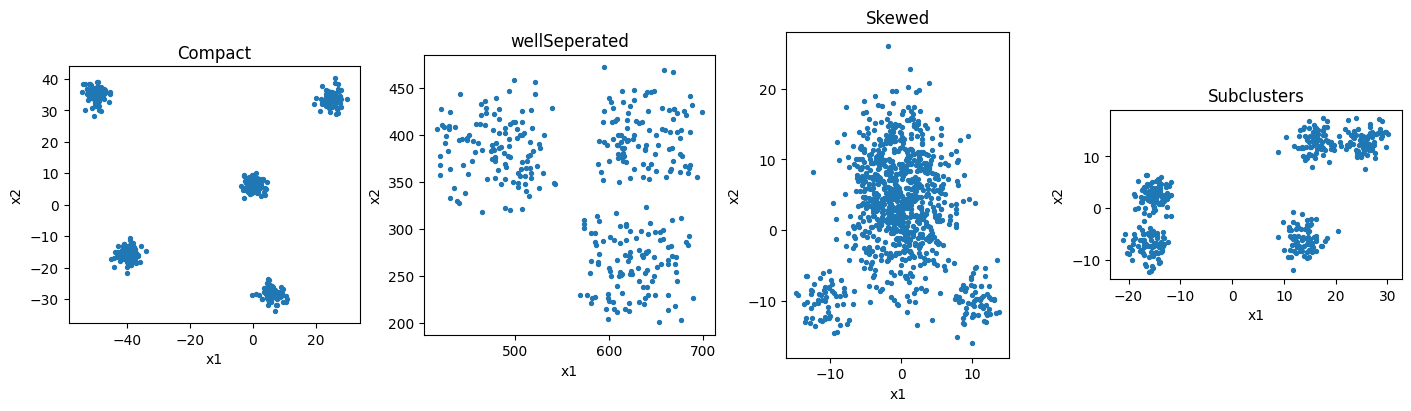

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4), layout="constrained")
for ax, (name, frame) in zip(axes, data.items()):
    ax.scatter(frame.x1, frame.x2, s=8)
    ax.set(title=name, xlabel="x1", ylabel="x2")
    ax.set_aspect("equal", adjustable="box")
plt.show()

Try k from 2 to 10, with 20 K-Means restarts and seed 42. Use the same chosen k for all four linkage methods.

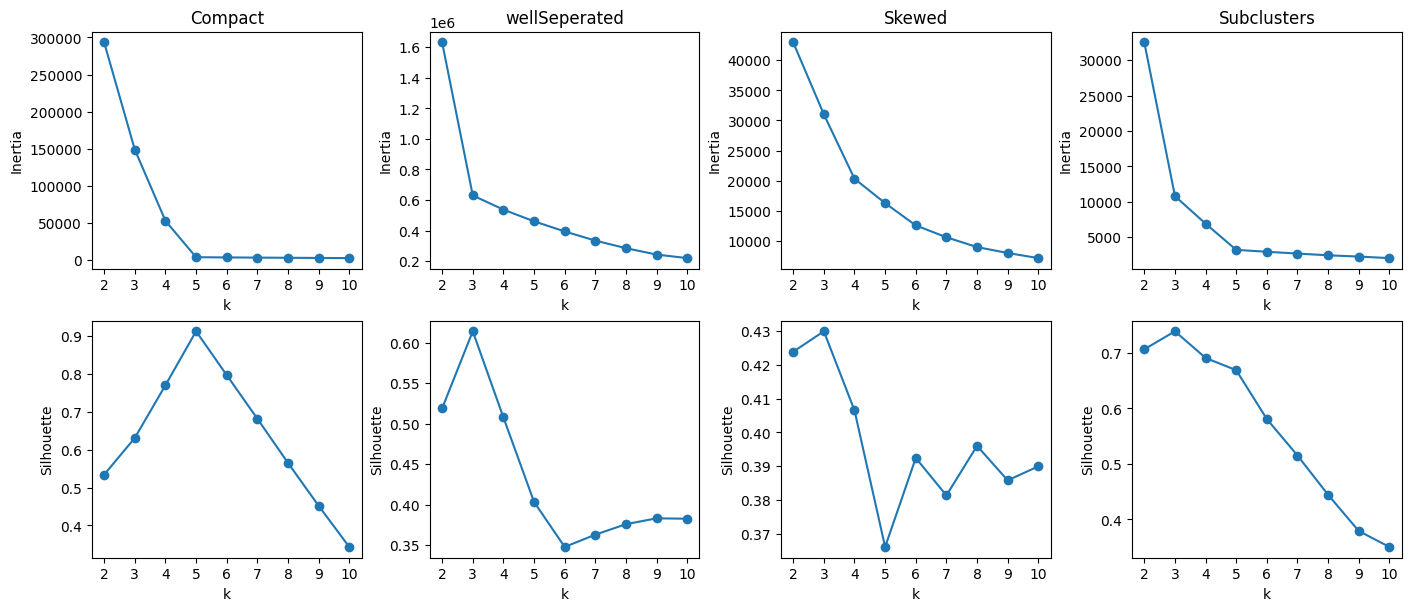

In [3]:
search = []
for name, frame in data.items():
    X = frame.to_numpy()
    for k in range(2, 11):
        model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        search.append([name, k, model.inertia_, silhouette_score(X, model.labels_)])
search = pd.DataFrame(search, columns=["Dataset", "k", "Inertia", "Silhouette"])

fig, axes = plt.subplots(2, 4, figsize=(14, 6), layout="constrained")
for j, name in enumerate(names):
    rows = search[search.Dataset == name]
    axes[0, j].plot(rows.k, rows.Inertia, "o-")
    axes[0, j].set(title=name, ylabel="Inertia", xlabel="k", xticks=range(2, 11))
    axes[1, j].plot(rows.k, rows.Silhouette, "o-")
    axes[1, j].set(ylabel="Silhouette", xlabel="k", xticks=range(2, 11))
plt.show()

Compact gives a clear choice of k=5. For wellSeperated, k=3 works well. Skewed also has its highest silhouette at 3 (0.430), but its elbow is less obvious.

Subclusters is less clear. Silhouette prefers 3 (0.739), while 5 gives 0.669. There is another bend in the inertia curve at 5, so use that to keep the smaller groups separate. Three is still a reasonable choice for broader groups; there are no labels to check against.

In [4]:
settings = pd.DataFrame({
    "k": [5, 3, 3, 5],
    "eps": [2.5, 25.0, 2.0, 2.0],
    "min_samples": [5, 5, 5, 5],
}, index=names)
settings

,k,eps,min_samples
Compact,5,2.5,5
wellSeperated,3,25.0,5
Skewed,3,2.0,5
Subclusters,5,2.0,5


For DBSCAN, use min_samples=5. This requires a few nearby points in 2D before calling an area dense, so isolated pairs do not form clusters. The distance plot uses five neighbours including the point itself, as DBSCAN does.

Choose eps near the bend in each plot: 2.5, 25, 2 and 2. Smaller values can break groups apart; larger values can join them. A single eps can struggle when groups have different densities.

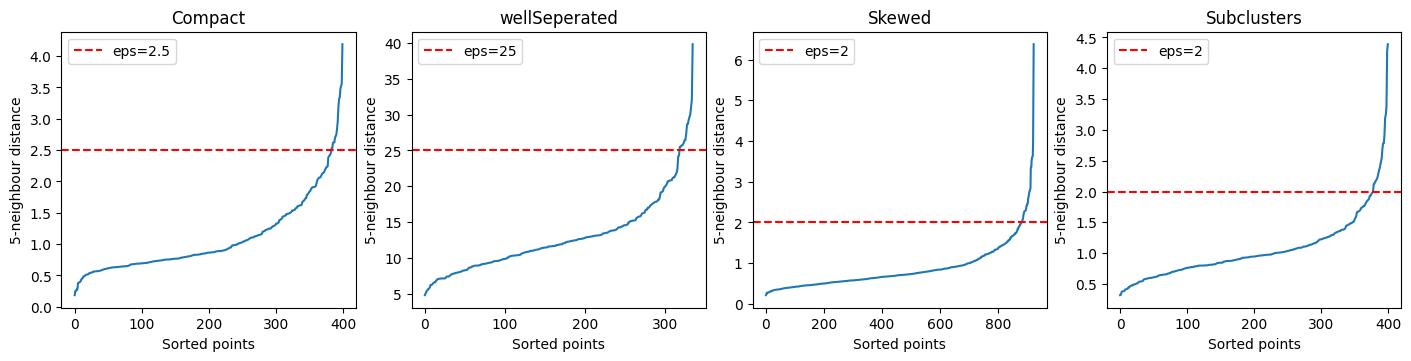

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), layout="constrained")
for ax, (name, frame) in zip(axes, data.items()):
    X = frame.to_numpy()
    neighbours = NearestNeighbors(n_neighbors=5).fit(X)
    distances = np.sort(neighbours.kneighbors(X)[0][:, -1])
    eps = settings.loc[name, "eps"]
    ax.plot(distances)
    ax.axhline(eps, color="red", linestyle="--", label=f"eps={eps:g}")
    ax.set(title=name, xlabel="Sorted points", ylabel="5-neighbour distance")
    ax.legend()
plt.show()

Grey points are DBSCAN noise. Cluster colours are separate for each plot, so blue need not mean the same group across methods.

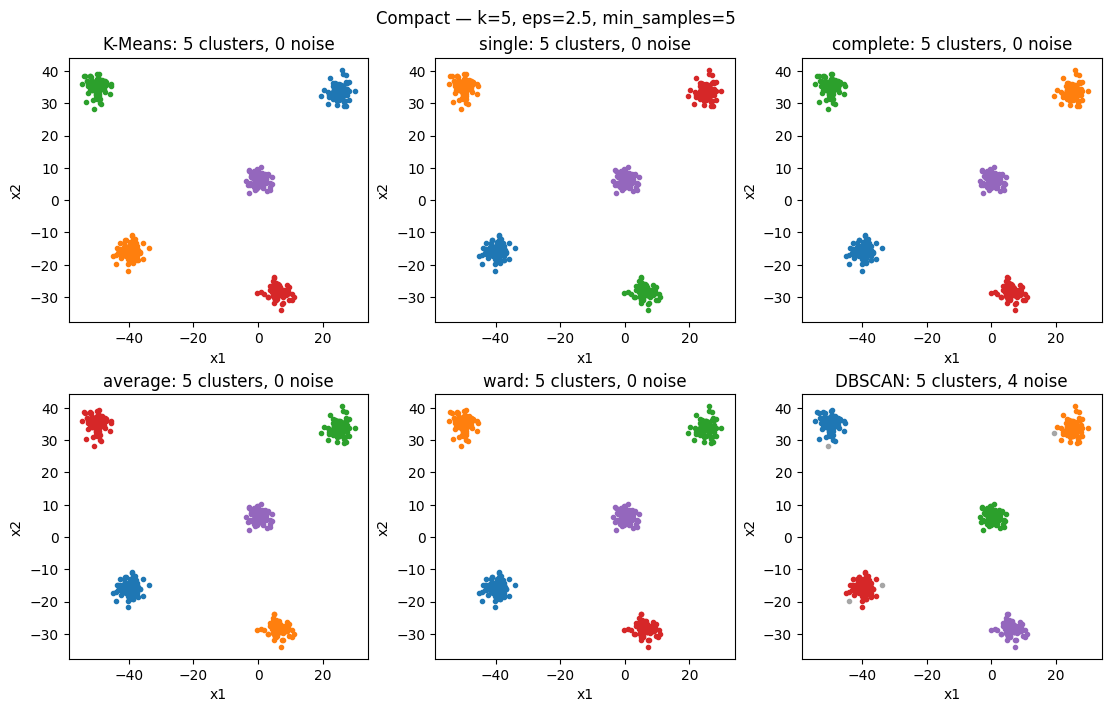

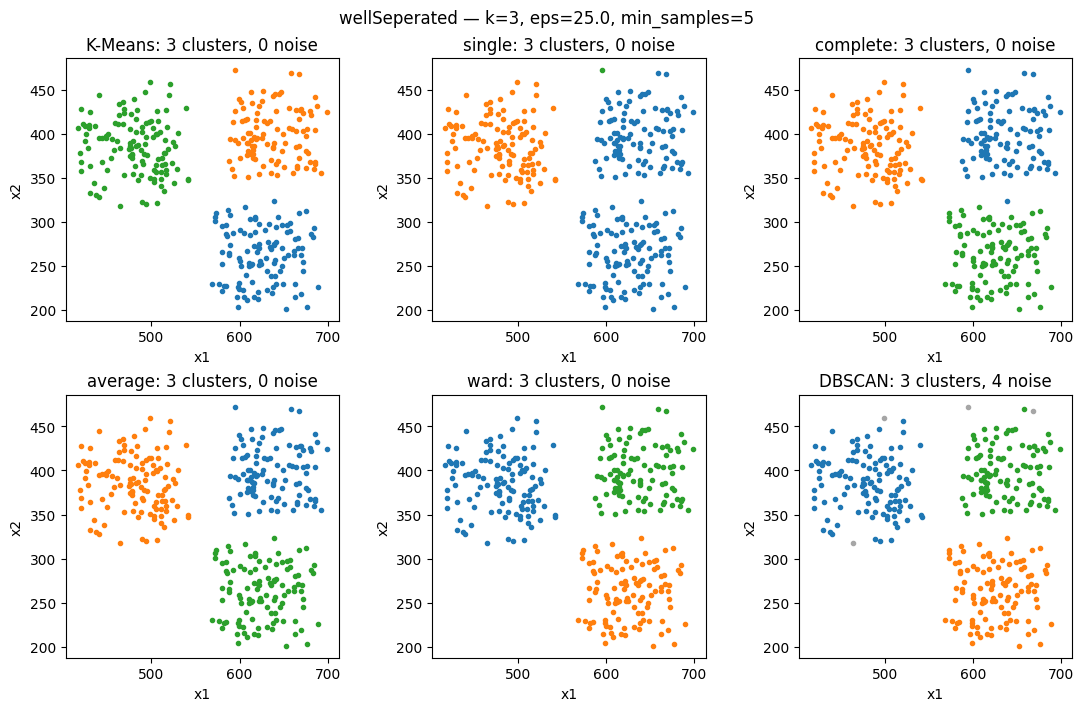

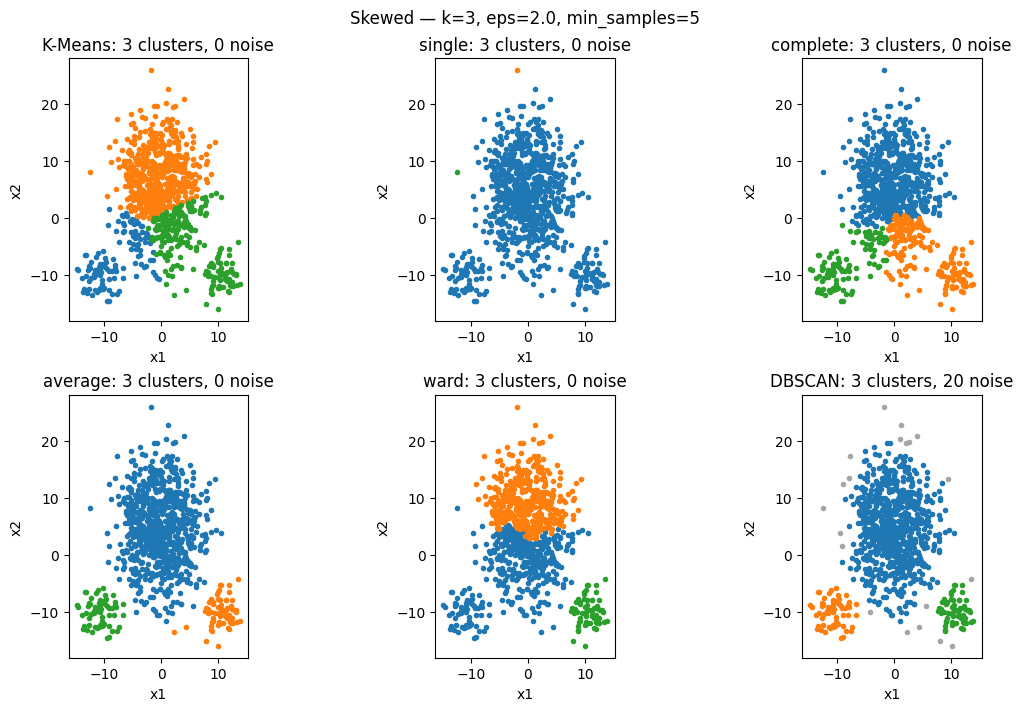

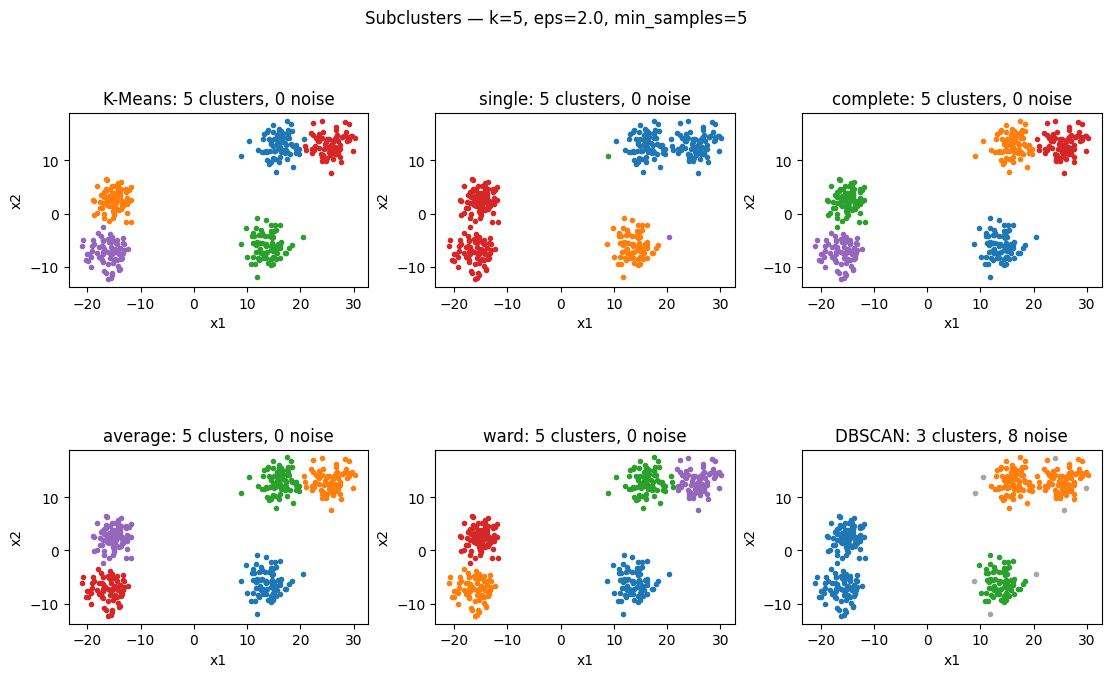

In [6]:
def plot_clusters(ax, X, labels):
    for label in np.unique(labels):
        points = X[labels == label]
        color = "0.65" if label == -1 else plt.get_cmap("tab10")(int(label) % 10)
        ax.scatter(points[:, 0], points[:, 1], s=9, color=color)
    ax.set(xlabel="x1", ylabel="x2")
    ax.set_aspect("equal", adjustable="box")

labels_by_model = {}
for name, frame in data.items():
    X = frame.to_numpy()
    k = int(settings.loc[name, "k"])
    eps = settings.loc[name, "eps"]
    models = {"K-Means": KMeans(n_clusters=k, n_init=20, random_state=42)}
    for method in ["single", "complete", "average", "ward"]:
        models[method] = AgglomerativeClustering(n_clusters=k, linkage=method)
    models["DBSCAN"] = DBSCAN(eps=eps, min_samples=5)

    fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
    fig.suptitle(f"{name} — k={k}, eps={eps}, min_samples=5")
    for ax, (method, model) in zip(axes.flat, models.items()):
        labels = model.fit_predict(X)
        labels_by_model[name, method] = labels
        plot_clusters(ax, X, labels)
        clusters = len(set(labels) - {-1})
        noise = int((labels == -1).sum())
        ax.set_title(f"{method}: {clusters} clusters, {noise} noise")
    plt.show()

The Ward dendrogram for Subclusters shows both cuts, at 3 and 5 groups. Only the last 12 branches are shown; numbers in parentheses are group sizes.

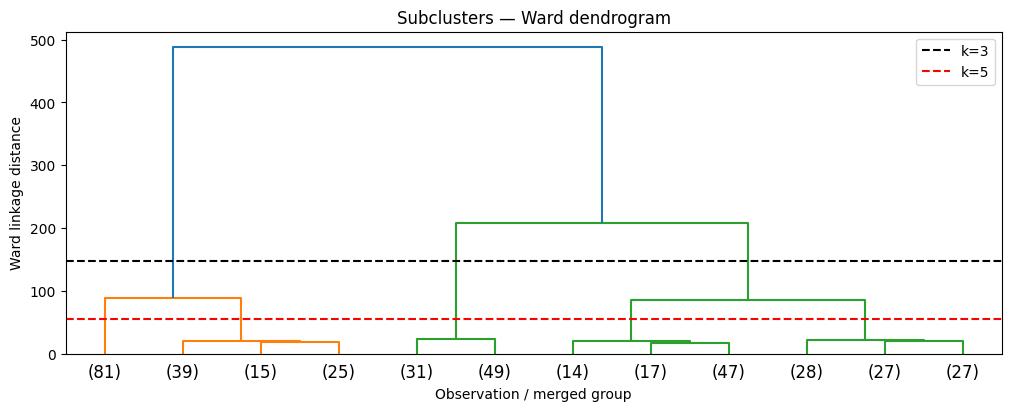

In [7]:
tree = linkage(data["Subclusters"].to_numpy(), method="ward")
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
dendrogram(tree, truncate_mode="lastp", p=12, ax=ax)
for k, color in [(3, "black"), (5, "red")]:
    height = (tree[-k, 2] + tree[-k + 1, 2]) / 2
    ax.axhline(height, color=color, linestyle="--", label=f"k={k}")
ax.set(title="Subclusters — Ward dendrogram", xlabel="Observation / merged group",
       ylabel="Ward linkage distance")
ax.legend()
plt.show()

## Scores

Higher silhouette and Calinski–Harabasz (CH), and lower Davies–Bouldin (DB), indicate better separation. Compare within each dataset. DBSCAN scores leave out noise; the noise percentage uses all points.

In [8]:
rows = []
for (name, method), labels in labels_by_model.items():
    X = data[name].to_numpy()
    keep = labels != -1
    clusters = len(np.unique(labels[keep]))
    silhouette = db = ch = np.nan
    if 2 <= clusters < keep.sum():
        silhouette = silhouette_score(X[keep], labels[keep])
        db = davies_bouldin_score(X[keep], labels[keep])
        ch = calinski_harabasz_score(X[keep], labels[keep])
    rows.append({"Dataset": name, "Method": method, "Clusters": clusters,
                 "Noise": int((~keep).sum()), "Noise %": 100 * (~keep).mean(),
                 "Silhouette": silhouette, "DB": db, "CH": ch})

scores = pd.DataFrame(rows)
scores.to_csv(BASE / "results/clustering_comparison.csv", index=False)

| Dataset | Method | Clusters | Noise | Noise % | Silhouette | DB | CH |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Compact | K-Means | 5 | 0 | 0.000 | 0.912 | 0.121 | 18329.591 |
| Compact | single | 5 | 0 | 0.000 | 0.912 | 0.121 | 18329.591 |
| Compact | complete | 5 | 0 | 0.000 | 0.912 | 0.121 | 18329.591 |
| Compact | average | 5 | 0 | 0.000 | 0.912 | 0.121 | 18329.591 |
| Compact | ward | 5 | 0 | 0.000 | 0.912 | 0.121 | 18329.591 |
| Compact | DBSCAN | 5 | 4 | 1.000 | 0.913 | 0.119 | 18873.762 |
| wellSeperated | K-Means | 3 | 0 | 0.000 | 0.614 | 0.547 | 792.053 |
| wellSeperated | single | 3 | 0 | 0.000 | 0.347 | 0.647 | 208.578 |
| wellSeperated | complete | 3 | 0 | 0.000 | 0.613 | 0.548 | 789.354 |
| wellSeperated | average | 3 | 0 | 0.000 | 0.614 | 0.547 | 792.053 |
| wellSeperated | ward | 3 | 0 | 0.000 | 0.614 | 0.547 | 792.053 |
| wellSeperated | DBSCAN | 3 | 4 | 1.194 | 0.616 | 0.543 | 800.171 |
| Skewed | K-Means | 3 | 0 | 0.000 | 0.430 | 0.872 | 716.911 |
| Skewed | single | 3 | 0 | 0.000 | 0.211 | 0.500 | 4.233 |
| Skewed | complete | 3 | 0 | 0.000 | 0.441 | 0.819 | 673.822 |
| Skewed | average | 3 | 0 | 0.000 | 0.492 | 0.488 | 433.846 |
| Skewed | ward | 3 | 0 | 0.000 | 0.372 | 0.840 | 635.928 |
| Skewed | DBSCAN | 3 | 20 | 2.162 | 0.501 | 0.476 | 441.093 |
| Subclusters | K-Means | 5 | 0 | 0.000 | 0.669 | 0.464 | 4583.013 |
| Subclusters | single | 5 | 0 | 0.000 | 0.528 | 0.376 | 1314.927 |
| Subclusters | complete | 5 | 0 | 0.000 | 0.668 | 0.465 | 4572.168 |
| Subclusters | average | 5 | 0 | 0.000 | 0.668 | 0.465 | 4572.168 |
| Subclusters | ward | 5 | 0 | 0.000 | 0.668 | 0.465 | 4574.703 |
| Subclusters | DBSCAN | 3 | 8 | 2.000 | 0.744 | 0.342 | 2631.147 |

Compact: K-Means and all four linkages give the same five groups (silhouette 0.912). K-Means works well here because the groups are compact and similar in size. DBSCAN removes four points and scores 0.913, which is barely different.

wellSeperated: K-Means, average and Ward give the same result (0.614), so any of these works well. Complete is close too. Single linkage joins groups through nearby points and leaves one point on its own: the chaining problem. DBSCAN finds three groups but removes four points.

Skewed: DBSCAN best follows the large cloud and two small groups in the plot (0.501), with 20 noise points. Average linkage is close (0.492) and keeps every point. K-Means and Ward split the large cloud: they reduce squared distances, so unequal group sizes and spread cause trouble. Complete also splits it because it limits cluster diameter. Single linkage chains 923 points together and leaves two singletons.

Subclusters: K-Means works for the five smaller groups (0.669); complete, average and Ward give similar results. Single joins nearby groups and leaves outlying points on their own. DBSCAN joins the smaller groups into three larger ones (0.744), with eight noise points. Its higher score does not mean it found the five groups better.

Adding clusters reduces within-cluster distances, eventually to zero with one point per cluster. This makes the raw sum unfair when cluster counts differ. Silhouette also favours compact, convex groups: it can reward splitting a long cluster or merging smaller groups, even when that misses the intended structure.

Leaving out noise can raise DBSCAN's scores because difficult points are removed before scoring. Here it drops 1.00%, 1.19%, 2.16% and 2.00% of the four datasets. Its scores therefore use fewer points than the other methods.

Docs used: [sklearn clustering](https://scikit-learn.org/stable/modules/clustering.html), [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html), [nearest neighbours](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html).